# Employee Attrition Prediction — Leakage-Free Pipeline, Threshold Tuning and Fairness Audit
**University of Dubai capstone** · Mahra Alhammadi, Raghd Ghanim, Eman Aboraya · Supervisor: Dr. Hamzah Alkhazaleh

This notebook implements the issue selected in our systematic literature review: published attrition results on the IBM HR dataset are inflated by
(1) oversampling before cross-validation and (2) choosing the best configuration on the test set, and (3) no study measures fairness.

**Sections**
1. Setup and data
2. Exploratory analysis (training set only)
3. Experiment A — leaky vs leakage-free SMOTE
4. Experiment B — test-set selection vs CV selection
5. Proposed pipeline: scale → SMOTE-NC → one-hot → model, tuned by PR-AUC
6. Threshold from out-of-fold predictions, single test evaluation
7. Fairness audit (gender, age)
8. Explanations (permutation importance, SHAP)
9. Split-to-split variability
10. Save the pipeline for the Streamlit dashboard

Dataset: add **IBM HR Analytics Employee Attrition & Performance** (`pavansubhasht/ibm-hr-analytics-attrition-dataset`) via *Add Input*.

In [1]:
!pip install -q imbalanced-learn shap 2>/dev/null
import os, glob, json, warnings
from sklearn.base import clone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV, cross_validate)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, average_precision_score,
                             accuracy_score, confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTENC, SMOTE, ADASYN, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
warnings.filterwarnings('ignore'); SEED = 42; np.random.seed(SEED)
sns.set_theme(style='whitegrid')

paths = glob.glob('/kaggle/input/**/WA_Fn-UseC_-HR-Employee-Attrition.csv', recursive=True) or glob.glob('**/*Attrition*.csv', recursive=True)
df_raw = pd.read_csv(paths[0], encoding='utf-8-sig')
print(df_raw.shape); df_raw.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Cleaning and the held-out test set
Constant fields and the identifier are dropped. **Gender and MaritalStatus are kept out of the model** and retained only for the fairness audit. The test set is split off first and not touched until Section 6.

In [2]:
df = df_raw.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])
y = (df.pop('Attrition') == 'Yes').astype(int).values
sensitive = df[['Gender', 'Age']].copy()
X = df.drop(columns=['Gender', 'MaritalStatus'])
CAT = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
X[CAT] = X[CAT].astype(object)
NUM = [c for c in X.columns if c not in CAT]
print(f'{len(df)} employees, {y.sum()} leavers ({y.mean():.1%}); {X.shape[1]} predictors; categorical: {CAT}')

Xtr, Xte, ytr, yte, Str, Ste = train_test_split(X, y, sensitive, test_size=0.2, stratify=y, random_state=SEED)
print('train', Xtr.shape, ytr.mean().round(3), '| test', Xte.shape, yte.mean().round(3))

1470 employees, 237 leavers (16.1%); 28 predictors; categorical: ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'OverTime']
train (1176, 28) 0.162 | test (294, 28) 0.16


## 2. Exploratory analysis (training set only)

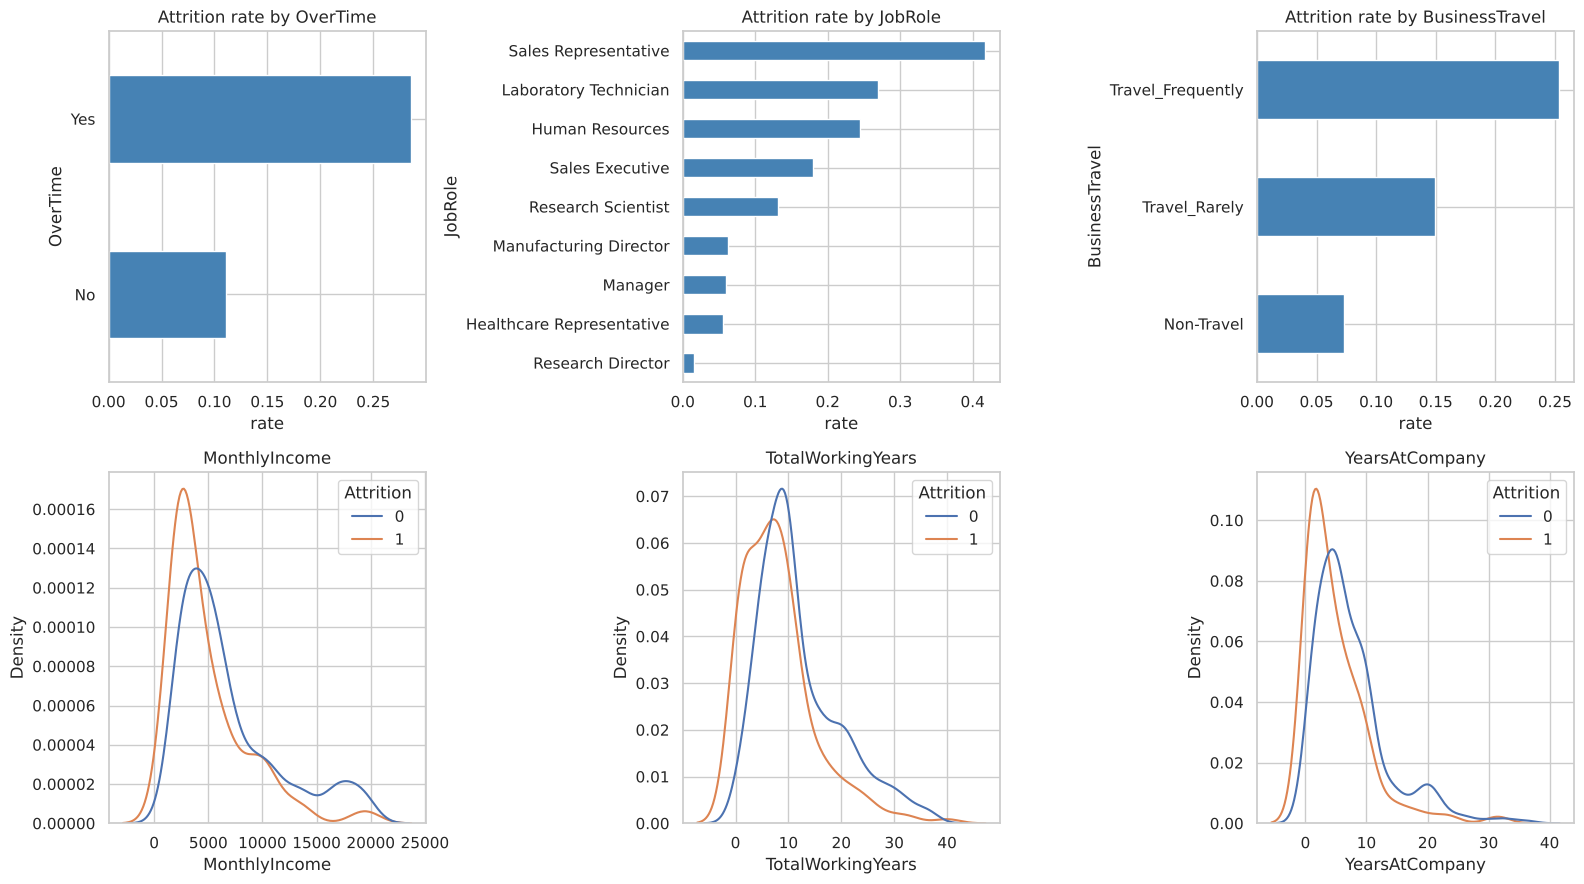

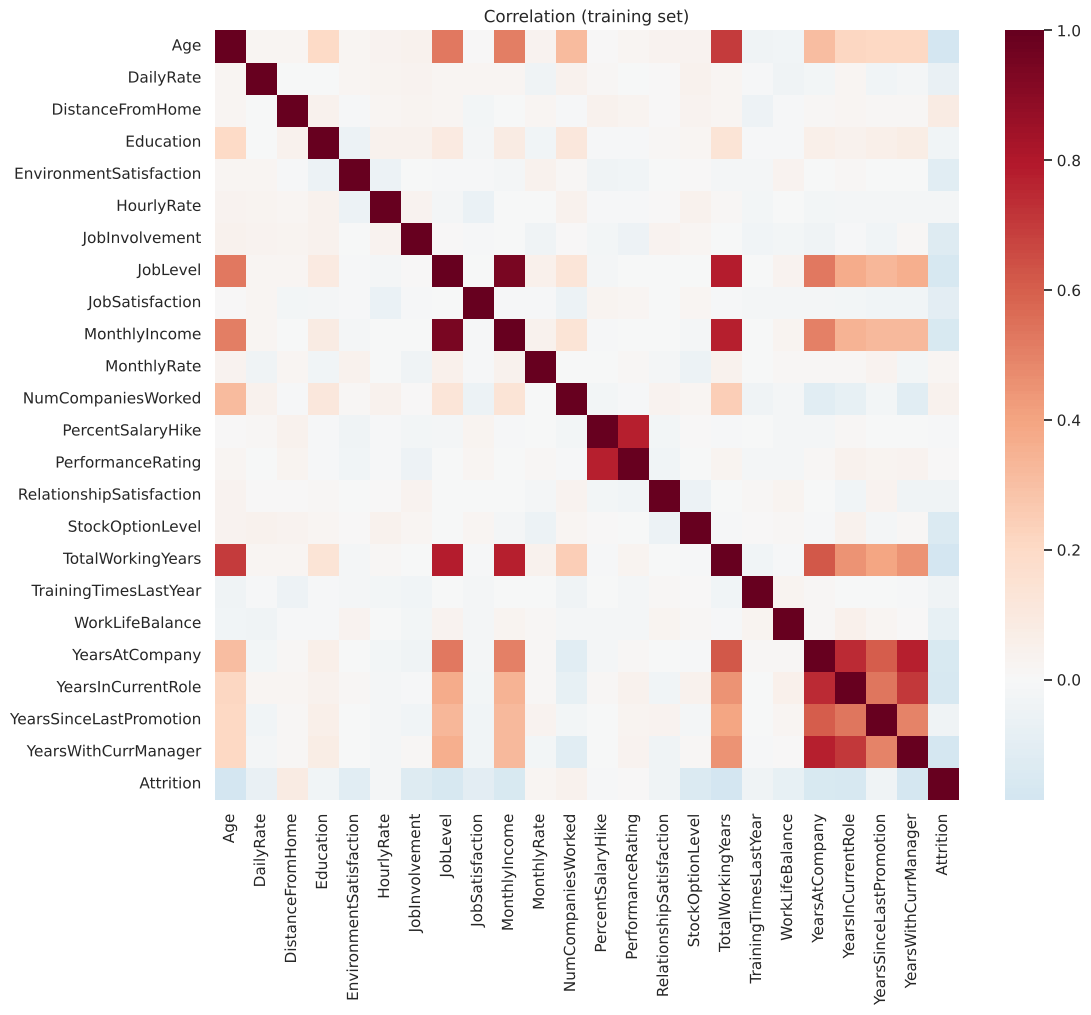

In [3]:
eda = Xtr.copy(); eda['Attrition'] = ytr
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(ax.flat[:3], ['OverTime', 'JobRole', 'BusinessTravel']):
    eda.groupby(col)['Attrition'].mean().sort_values().plot.barh(ax=a, color='steelblue'); a.set_title(f'Attrition rate by {col}'); a.set_xlabel('rate')
for a, col in zip(ax.flat[3:], ['MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany']):
    sns.kdeplot(data=eda, x=col, hue='Attrition', common_norm=False, ax=a); a.set_title(col)
plt.tight_layout(); plt.show()
plt.figure(figsize=(12, 10)); sns.heatmap(eda[NUM + ['Attrition']].corr(), cmap='RdBu_r', center=0); plt.title('Correlation (training set)'); plt.show()

## 3. Pipeline builder and metric helper
Order inside every fold: **scale numeric → SMOTE-NC (categoricals still raw) → one-hot encode → model**. Everything is fitted on the training portion of the fold only.

In [4]:
def pipe(model, balance='smotenc'):
    scale = ColumnTransformer([('num', StandardScaler(), NUM)], remainder='passthrough',
                              verbose_feature_names_out=False).set_output(transform='pandas')
    enc = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)], remainder='passthrough')
    steps = [('scale', scale)]
    if balance == 'smotenc':
        steps.append(('smote', SMOTENC(categorical_features=CAT, random_state=SEED)))
    return ImbPipeline(steps + [('ohe', enc), ('model', model)])

def metrics(yt, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(yt, yh), precision=precision_score(yt, yh, zero_division=0), recall=recall_score(yt, yh),
                f1=f1_score(yt, yh), roc_auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p))

## 4. Experiment A — SMOTE before vs inside cross-validation
Same data, same Random Forest. The leaky version resamples the whole dataset and then cross-validates, the protocol found in many published studies.

,accuracy,precision,recall,f1,roc_auc,pr_auc
Leaky: SMOTE before CV,0.933,0.96,0.904,0.931,0.982,0.985
SMOTE-NC inside folds,0.859,0.61,0.350,0.445,0.817,0.541
No resampling,0.861,0.80,0.186,0.301,0.809,0.541


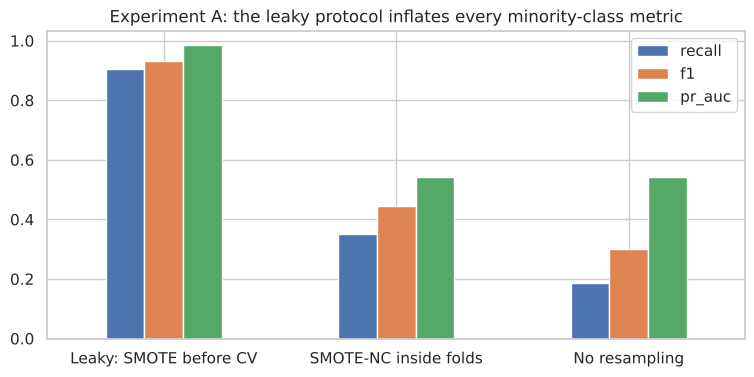

In [5]:
X_oh = pd.get_dummies(X, columns=CAT).astype(float)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
Xs, ys = SMOTE(random_state=SEED).fit_resample(MinMaxScaler().fit_transform(X_oh), y)
res_A = {
  'Leaky: SMOTE before CV': metrics(ys, cross_val_predict(rf, Xs, ys, cv=cv, method='predict_proba')[:, 1]),
  'SMOTE-NC inside folds':  metrics(y, cross_val_predict(pipe(rf), X, y, cv=cv, method='predict_proba')[:, 1]),
  'No resampling':          metrics(y, cross_val_predict(pipe(rf, None), X, y, cv=cv, method='predict_proba')[:, 1]),
}
res_A = pd.DataFrame(res_A).T.round(3); display(res_A)
res_A[['recall', 'f1', 'pr_auc']].plot.bar(figsize=(9, 4), rot=0, title='Experiment A: the leaky protocol inflates every minority-class metric'); plt.show()

## 5. Experiment B — 'top-1 on the test set' vs selection by cross-validation
32 configurations (2 scalers × 4 balancers × 4 models), repeated over 10 random splits. For each split we record the best test F1 (what a top-1 table reports) and the test F1 of the configuration a cross-validation on the training data would have chosen.

In [6]:
configs = [(sc, bal, m) for sc in ['minmax', 'standard'] for bal in ['none', 'smote', 'adasyn', 'ros'] for m in ['lr', 'rf', 'gb', 'ab']]
def make_simple(sc, bal, m):
    models = {'lr': LogisticRegression(max_iter=2000), 'rf': RandomForestClassifier(200, random_state=SEED, n_jobs=-1),
              'gb': GradientBoostingClassifier(random_state=SEED), 'ab': AdaBoostClassifier(random_state=SEED)}
    bals = {'smote': SMOTE(random_state=SEED), 'adasyn': ADASYN(random_state=SEED), 'ros': RandomOverSampler(random_state=SEED)}
    steps = [('sc', MinMaxScaler() if sc == 'minmax' else StandardScaler())] + ([('bal', bals[bal])] if bal != 'none' else []) + [('m', models[m])]
    return ImbPipeline(steps)
rows = []
for rep in range(10):
    a, b, c, d = train_test_split(X_oh.values, y, test_size=0.2, stratify=y, random_state=rep)
    icv = StratifiedKFold(3, shuffle=True, random_state=rep); tf, cf = [], []
    for cfg in configs:
        p = make_simple(*cfg)
        cf.append(cross_validate(p, a, c, cv=icv, scoring='f1')['test_score'].mean())
        p.fit(a, c); tf.append(f1_score(d, p.predict(b)))
    tf, cf = np.array(tf), np.array(cf)
    rows.append(dict(split=rep, best_on_test=tf.max(), chosen_by_cv=tf[cf.argmax()], median_config=np.median(tf)))
res_B = pd.DataFrame(rows); display(res_B.round(3)); display(res_B.mean().round(3))
print('Average optimism of top-1 reporting:', round((res_B.best_on_test - res_B.chosen_by_cv).mean(), 3), 'F1 points')

,split,best_on_test,chosen_by_cv,median_config
0,0,0.545,0.394,0.432
1,1,0.613,0.514,0.511
2,2,0.538,0.500,0.477
3,3,0.575,0.545,0.482
4,4,0.568,0.460,0.463
5,5,0.507,0.429,0.429
6,6,0.571,0.568,0.506
7,7,0.674,0.519,0.520
8,8,0.575,0.430,0.454
9,9,0.556,0.552,0.406


split            4.500
best_on_test     0.572
chosen_by_cv     0.491
median_config    0.468
dtype: float64

Average optimism of top-1 reporting: 0.081 F1 points


## 6. Proposed pipeline — tuning by PR-AUC, SMOTE-NC vs class weights
Grid search with 5-fold stratified CV on the training set only. Each model is tried with SMOTE-NC and without resampling (class_weight='balanced' for LR and RF; plain for GB, which has no class_weight).

In [7]:
grids = {
  'LR': (LogisticRegression(max_iter=3000), {'model__C': [0.01, 0.1, 1, 10]}),
  'RF': (RandomForestClassifier(random_state=SEED, n_jobs=-1), {'model__n_estimators': [300], 'model__max_depth': [4, 8, None], 'model__min_samples_leaf': [1, 5]}),
  'GB': (GradientBoostingClassifier(random_state=SEED), {'model__n_estimators': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]}),
}
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED); comp, fitted = [], {}
for name, (m, g) in grids.items():
    for bal in ['smotenc', 'weights']:
        mm = m.__class__(**m.get_params())
        if bal == 'weights' and name != 'GB': mm.set_params(class_weight='balanced')
        gs = GridSearchCV(pipe(mm, 'smotenc' if bal == 'smotenc' else None), g, scoring='average_precision', cv=cv5).fit(Xtr, ytr)
        oof = cross_val_predict(gs.best_estimator_, Xtr, ytr, cv=cv5, method='predict_proba')[:, 1]
        pr, rc, th = precision_recall_curve(ytr, oof); f1s = 2 * pr * rc / (pr + rc + 1e-12)
        thr = float(th[np.nanargmax(f1s[:-1])]); mo = metrics(ytr, oof, thr)
        comp.append(dict(model=name, balance=bal, cv_pr_auc=gs.best_score_, threshold=thr, oof_f1=mo['f1'], oof_recall=mo['recall'], oof_precision=mo['precision'], oof_roc_auc=mo['roc_auc']))
        fitted[(name, bal)] = (gs.best_estimator_, thr, oof)
comp = pd.DataFrame(comp).sort_values('cv_pr_auc', ascending=False); display(comp.round(3))

,model,balance,cv_pr_auc,threshold,oof_f1,oof_recall,oof_precision,oof_roc_auc
1,LR,weights,0.627,0.604,0.596,0.621,0.573,0.823
4,GB,smotenc,0.614,0.405,0.554,0.526,0.585,0.824
5,GB,weights,0.612,0.273,0.574,0.579,0.570,0.819
0,LR,smotenc,0.578,0.588,0.560,0.616,0.513,0.813
3,RF,weights,0.567,0.485,0.518,0.563,0.480,0.803
2,RF,smotenc,0.559,0.366,0.512,0.621,0.435,0.801


## 7. Final evaluation — one look at the test set
The model with the best cross-validated PR-AUC and its out-of-fold threshold are applied to the test set once.

Selected: LR weights


,accuracy,precision,recall,f1,roc_auc,pr_auc
threshold 0.60 (chosen on CV),0.844,0.510,0.553,0.531,0.782,0.575
threshold 0.50 (default),0.741,0.341,0.660,0.449,0.782,0.575


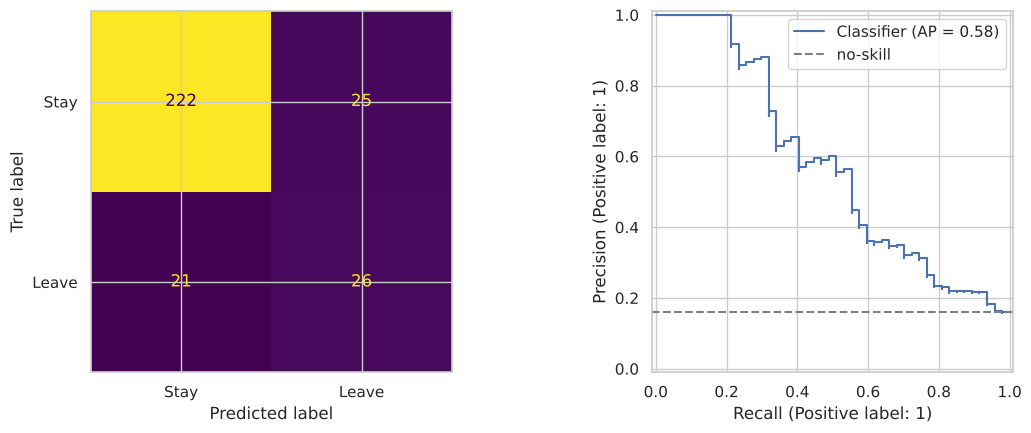

In [8]:
best = comp.iloc[0]; est, thr, oof = fitted[(best.model, best.balance)]
pte = est.predict_proba(Xte)[:, 1]
final = pd.DataFrame({f'threshold {thr:.2f} (chosen on CV)': metrics(yte, pte, thr), 'threshold 0.50 (default)': metrics(yte, pte, 0.5)}).T.round(3)
print('Selected:', best.model, best.balance); display(final)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yte, (pte >= thr).astype(int)), display_labels=['Stay', 'Leave']).plot(ax=ax[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(yte, pte, ax=ax[1]); ax[1].axhline(yte.mean(), ls='--', c='grey', label='no-skill'); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Fairness audit
Recall (share of real leavers caught), precision and false-positive rate per group, on out-of-fold training predictions (larger sample) and on the test set. Gender and MaritalStatus were **not** model inputs; **Age was** a model input and is also used here to define the age groups.

,n,leavers,base_rate,recall,precision,fpr,flagged
group,,,,,,,
Female,472,71,0.150,0.676,0.565,0.092,0.180
Male,704,119,0.169,0.588,0.579,0.087,0.172
Age<30,258,74,0.287,0.811,0.594,0.223,0.391
Age 30-45,693,91,0.131,0.571,0.553,0.070,0.136
Age>45,225,25,0.111,0.240,0.545,0.025,0.049


,n,leavers,base_rate,recall,precision,fpr,flagged
group,,,,,,,
Female,116,16,0.138,0.625,0.526,0.090,0.164
Male,178,31,0.174,0.516,0.500,0.109,0.180
Age<30,68,17,0.250,0.647,0.478,0.235,0.338
Age 30-45,178,21,0.118,0.667,0.519,0.083,0.152
Age>45,48,9,0.188,0.111,1.000,0.000,0.021


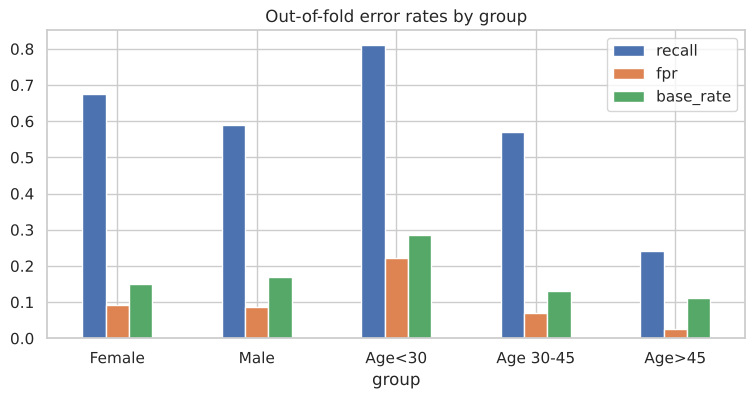

In [9]:
def audit(yt, p, thr, S):
    groups = {'Female': S.Gender.values == 'Female', 'Male': S.Gender.values == 'Male',
              'Age<30': S.Age.values < 30, 'Age 30-45': (S.Age.values >= 30) & (S.Age.values <= 45), 'Age>45': S.Age.values > 45}
    out = []
    for g, mk in groups.items():
        tn, fp, fn, tp = confusion_matrix(yt[mk], (p[mk] >= thr).astype(int), labels=[0, 1]).ravel()
        out.append(dict(group=g, n=int(mk.sum()), leavers=int(yt[mk].sum()), base_rate=yt[mk].mean(), recall=tp / max(tp + fn, 1),
                        precision=tp / max(tp + fp, 1), fpr=fp / max(fp + tn, 1), flagged=(p[mk] >= thr).mean()))
    return pd.DataFrame(out).set_index('group')
fair_oof, fair_test = audit(ytr, oof, thr, Str), audit(yte, pte, thr, Ste)
display(fair_oof.round(3)); display(fair_test.round(3))
fair_oof[['recall', 'fpr', 'base_rate']].plot.bar(figsize=(9, 4), rot=0, title='Out-of-fold error rates by group'); plt.show()

## 9. What drives the predictions
Permutation importance (drop in test PR-AUC) for the whole pipeline, then SHAP on the fitted model. Importance shows what the **model** relies on — it is not evidence that changing a factor would make anyone stay.

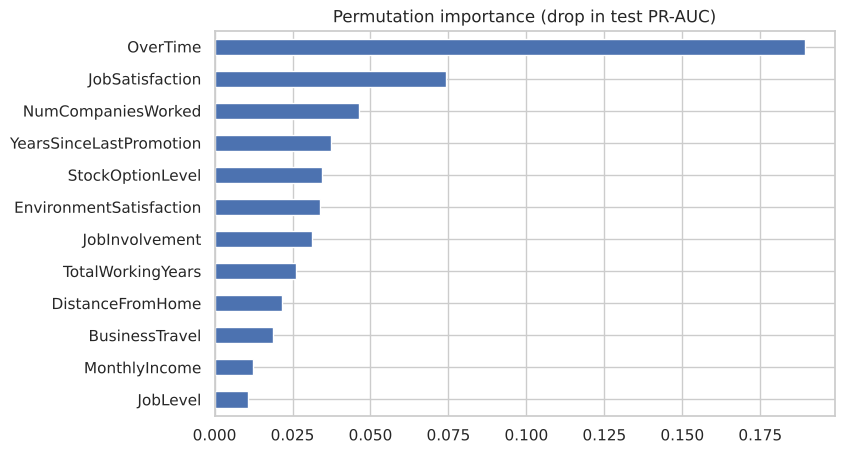

Background dataset has 1176 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1176 when initializing the masker.


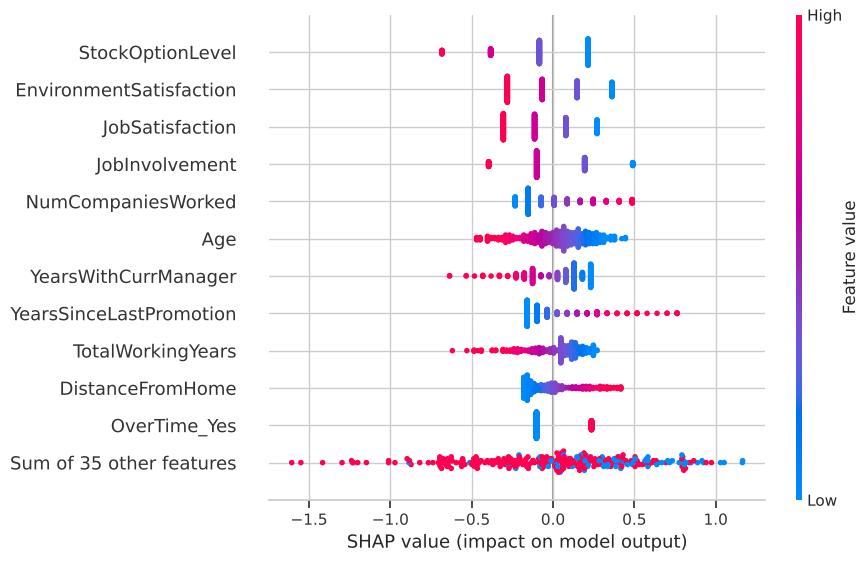

In [10]:
pi = permutation_importance(est, Xte, yte, scoring='average_precision', n_repeats=20, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()[-12:]
imp.plot.barh(figsize=(8, 5), title='Permutation importance (drop in test PR-AUC)'); plt.show()

import shap
pre = ImbPipeline([s for s in est.steps if s[0] in ('scale', 'ohe')])
Xte_t = pre.transform(Xte); names = [n.split('__')[-1] for n in est.named_steps['ohe'].get_feature_names_out()]
model = est.named_steps['model']
explainer = shap.LinearExplainer(model, pre.transform(Xtr)) if best.model == 'LR' else shap.TreeExplainer(model)
sv = explainer(pd.DataFrame(Xte_t, columns=names))
if sv.values.ndim == 3: sv = sv[:, :, 1]
shap.plots.beeswarm(sv, max_display=12)

## 10. How much would results move on a different split?

,accuracy,precision,recall,f1,roc_auc,pr_auc
mean,0.858,0.554,0.594,0.572,0.824,0.621
std,0.020,0.059,0.060,0.053,0.023,0.053
min,0.810,0.421,0.447,0.462,0.781,0.467
max,0.884,0.638,0.681,0.638,0.856,0.694


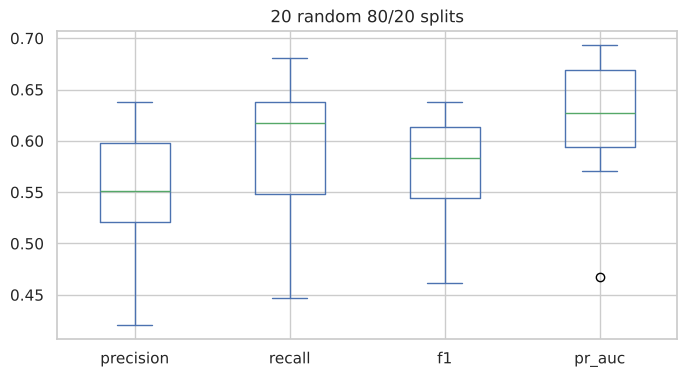

In [11]:
var = []
for rep in range(20):
    a, b, c, d = train_test_split(X, y, test_size=0.2, stratify=y, random_state=100 + rep)
    e = clone(est).fit(a, c); var.append(metrics(d, e.predict_proba(b)[:, 1], thr))
var = pd.DataFrame(var); display(var.describe().loc[['mean', 'std', 'min', 'max']].round(3))
var[['precision', 'recall', 'f1', 'pr_auc']].plot.box(figsize=(8, 4), title='20 random 80/20 splits'); plt.show()

## 11. Save the pipeline for the Streamlit dashboard

In [12]:
import joblib
joblib.dump({'pipeline': est, 'threshold': thr, 'features': list(X.columns)}, 'attrition_pipeline.joblib')
print('Saved attrition_pipeline.joblib — load it in Streamlit with joblib.load() and call pipeline.predict_proba(df)[:, 1]')

Saved attrition_pipeline.joblib — load it in Streamlit with joblib.load() and call pipeline.predict_proba(df)[:, 1]
